# Shopping event activity
Google Merchandise Store · listopad 2020

Notebook wczytuje trzy zagregowane eksporty BigQuery, sprawdza ich jakość
i pokazuje liczbę unikalnych użytkowników według zdarzenia.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

data_dir = Path("../data") if Path.cwd().name == "python" else Path("data")
exports = {
    "Shopping events": (
        "funnel_events_nov2020.csv",
        ["event_name", "users"],
    ),
    "Daily purchasers": (
        "daily_purchases_nov2020.csv",
        ["date", "purchasers"],
    ),
    "Device conversion": (
        "device_conversion_nov2020.csv",
        ["device_type", "product_viewers", "purchasers", "viewers_who_purchased", "conversion_rate_pct"],
    ),
}

## Data quality and exploration

Pierwsza kolumna każdego eksportu identyfikuje wiersz. Zestawienie pokazuje
wymiary plików, liczbę brakujących pól i liczbę powtórzonych kluczy.

In [2]:
tables = {}
quality_checks = []
for name, (filename, columns) in exports.items():
    path = data_dir / filename
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}. See data/README.md for export steps.")

    table = pd.read_csv(path)
    if table.columns.tolist() != columns or not isinstance(table.index, pd.RangeIndex):
        raise ValueError(f"{filename}: expected columns {columns} and consistent row lengths.")

    key = columns[0]
    table[key] = table[key].astype("string").str.strip().replace("", pd.NA)
    quality_checks.append({
        "export": name,
        "rows": len(table),
        "columns": len(table.columns),
        "missing cells": int(table.isna().sum().sum()),
        "duplicate keys": int(table[key].duplicated().sum()),
    })
    tables[name] = table

quality = pd.DataFrame(quality_checks).set_index("export")
display(quality)
if quality[["missing cells", "duplicate keys"]].to_numpy().any():
    raise ValueError("Resolve missing values or duplicate keys before plotting.")

event_labels = {
    "view_item": "Viewed product",
    "add_to_cart": "Added to cart",
    "begin_checkout": "Began checkout",
    "purchase": "Purchased",
}
events = tables["Shopping events"].set_index("event_name")
if set(events.index) != set(event_labels):
    raise ValueError("Expected the four shopping event types defined in event_labels.")
if not pd.api.types.is_integer_dtype(events["users"]) or events["users"].lt(0).any():
    raise ValueError("The users column must contain nonnegative integers.")

ordered_events = events.loc[list(event_labels)]
ordered_counts = ordered_events["users"].tolist()
display(ordered_events)
display(tables["Daily purchasers"].head())
display(tables["Device conversion"])

,rows,columns,missing cells,duplicate keys
export,,,,
Shopping events,4,2,0,0
Daily purchasers,30,2,0,0
Device conversion,2,5,0,0


,users
event_name,
view_item,21440
add_to_cart,2060
begin_checkout,4219
purchase,1532


,date,purchasers
0,2020-11-01,13
1,2020-11-02,39
2,2020-11-03,46
3,2020-11-04,30
4,2020-11-05,26


,device_type,product_viewers,purchasers,viewers_who_purchased,conversion_rate_pct
0,mobile,8588,644,638,7.43
1,desktop,12497,863,853,6.83


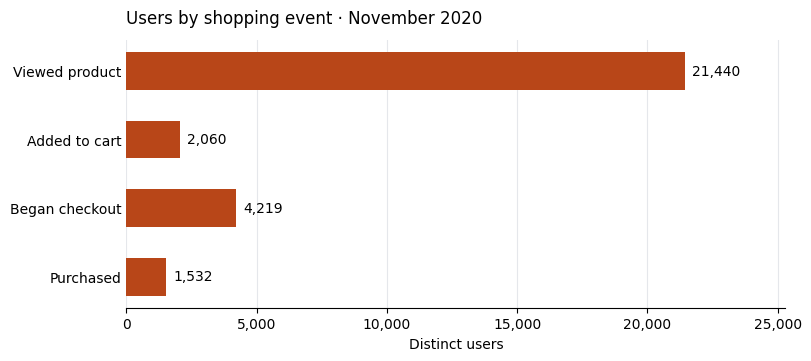

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
labels = list(event_labels.values())
bars = ax.barh(labels, ordered_counts, height=0.55, color="#B84618")
ax.bar_label(bars, labels=[f"{count:,}" for count in ordered_counts], padding=5)
ax.invert_yaxis()
ax.set_xlim(0, max(ordered_counts) * 1.18 or 1)
ax.set_title("Users by shopping event · November 2020", loc="left", pad=12)
ax.set_xlabel("Distinct users")
ax.xaxis.set_major_formatter("{x:,.0f}")
ax.set_axisbelow(True)
ax.grid(axis="x", color="#E5E7EB")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.show()

## Interpretation

Product views reached the most users (21,440), and 1,532 users purchased.
Checkout reached 4,219 users, compared with 2,060 for add-to-cart.
Each bar counts users independently. The order on the chart reflects the
usual shopping journey, and the counts alone cannot establish step-to-step drop-off.